# LIVRABLE PROJET 1 EDA pour l'entreprise Academy
***EDA pour un projet d'expansion intl. de la Sté ACADEMY sur ses produits de formation en ligne parcours Lycée et Université***  
***Base de l'EDA : Jeux de données de la banque mondiale.***

## Table des matières

- [CHARGEMENTS DES LIBRAIRIES](#CHARGEMENTS-DES-LIBRAIRIES)
- [CHARGEMENTS DES DATAFRAMES](#CHARGEMENTS-DES-DATAFRAMES)
  - [MISE EN PAGE](#MISE-EN-PAGE)
- [INTRODUCTION](#INTRODUCTION)
- [PARTIE I - Business understanding : Expansion à l'international de Academy](#PARTIE-I---Business-understanding-:-Expansion-à-l'international-de-Academy)
- [PARTIE II - Data understanding](#PARTIE-II---Data-understanding)
- [PARTIE III - Data preparation](#PARTIE-III---Data-preparation)
  - [Module de description](#Module-de-description)
  - [Module de nettoyage](#Module-de-nettoyage)
  - [Initialisation des nouveaux dataframes (avec filtre/nettoyés)](#Initialisation-des-nouveaux-dataframes-(avec-filtre/nettoyés))
  - [1 - Description du jeux de données](#1---Description-du-jeux-de-données)
  - [2 - Reduction du périmètre](#2---Reduction-du-périmètre)
    - [1. Les années et leur complétude](#1.-Les-années-et-leur-complétude)
    - [2. Complétude des indicateurs : Top 20 en %](#2.-Complétude-des-indicateurs-:-Top-20-en-%)
    - [3. Table de complétude des pays : Top 20 en %](#3.-Table-de-complétude-des-pays-:-Top-20-en-%)
    - [4. Tableau croisé pour identifier les indicateurs les plus pertinents](#4.-Tableau-croisé-pour-identifier-les-indicateurs-les-plus-pertinents)
    - [4.1 Indicateurs finaux](#4.1-Indicateurs-finaux)
    - [5. Création du dataframe final pour visualisation](#5.-Création-du-dataframe-final-pour-visualisation)
- [PARTIE IV - Visualisation](#PARTIE-IV---Visualisation)
  - [1 - Production des heatmap](#1---Production-des-heatmap)
  - [2 - Production des statistiques individuelle par indicateurs](#2---Production-des-statistiques-individuelle-par-indicateurs)
  - [Indicateurs World Bank — Sélection finale projet Academy, détails des indicateurs](#Indicateurs-World-Bank-—-Sélection-finale-projet-Academy,-détails-des-indicateurs)
- [Conclusion](#Conclusion)

## CHARGEMENTS DES LIBRAIRIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sns

## CHARGEMENTS DES DATAFRAMES
Initialisation de tous les dataframes dans des variables afin que le notebook n'ait à le charger qu'une seule fois et pas à chaque fois qu'on appelle une fonction.

In [2]:
# Permet de charger dans des variables "df_...", les dataframe ".csv". en dehors des fonctions pour eviter le chargement du fichier avec la fonction
df_data = pd.read_csv("EdStatsData.csv")
df_country = pd.read_csv("EdStatsCountry.csv")
df_series = pd.read_csv("EdStatsSeries.csv")
df_country_series = pd.read_csv("EdStatsCountry-Series.csv")
df_foot = pd.read_csv("EdStatsFootNote.csv")

## MISE EN PAGE
#### La fonction "titre"
La fonction "titre" améliore la lisibilité des sorties du code en délimitant les résultats par un titre ce qui améliore la lisibilité.
#### La fonction "listing"
La fonction listing est une fonction qui me permet d'avoir rapidement le listing des occurrences d'une colonne pour la consulter.


In [3]:
def titre(txt, n=40):
    print('-'*n)
    print(txt)
    print('-'*n)

def listing(df,col):
        display(df[col].unique().tolist())

# INTRODUCTION
L'exercice est réalisé en  suivant l'approche **CRISP-DM**. Cette approche me permettra, à la manière d'une check-list, de cadrer et orienter le travail d'EDA sans omettre des points importants.
# PARTIE I - Business understanding : Expansion à l'international de Academy

#### a. Entreprise
Start-up de la EdTech, nommée *__academy__*, qui propose des contenus de formation en ligne pour un public de niveau lycée et université.
#### b. Stratégie
L'entreprise tente d'opérer une expansion à l'international. Elle mène des recherches exploratoires dans ce sens.
#### c. Mission
**EDA** pour déterminer si les données sur l'éducation de la banque mondiale permettent d'enrichir la réflexion autour du projet d'expansion.  
- *Explorer les datasets et identifier les pays avec un fort potentiel de clients pour les services de *__academy__*.* 
- *Comprendre comment ce potentiel pourrait évoluer.*  
#### d. Problématique
Que faut il conserver et traiter pour fournir des insights pour déterminer et décider du ou des pays ou s'installer ?

# PARTIE II - Data understanding

### 1. Qu'est ce qu'une ligne, ici ?
- Une ligne est une observation, une donnée qui se  distribue sur plusieurs variables. Parfois elles sont le résultat de faits issues d'une source de données (données brutes ou sources) sur un temps donné (recensement de personnes scolarisées dans le primaire en telle année).  
- Parfois elles sont issues de champs calculés c'est-à-dire d'un calcul de plusieurs variables ( Région Europe, calcule la moyenne des étudiants dans le secondaire). Parfois elles sont combinées, c'est ce que l'on va retrouver dans les codes séries, plusieurs variables assemblées pour fournir un insight particulier.  
- En conclusion, cela peut être un pays si c'est pour le caractériser nominativement, mais ce n'est pas systématique, voire peu le cas car un  pays a presque toujours plusieurs insights qui lui sont propres, du coup le pays se répétera plusieurs fois dans une même table.
- Toutefois pour la table EdStatsCountry, table de dimension, il se peut que les pays ne se retrouvent qu'une fois car ce sont des clés primaires. Cela signifie l'on va y définir chaque pays individuellement et que les autres tables vont l'interroger en cas de besoin.

### 2. Les bases de données  
Nous avons 5 bases de données portant sur l'éducation dans le monde entier. Ces datasets de la Banque Mondiale proviennent de programmes d'études de la Banque Mondiale. Ce sont tous des fichiers .csv :
- **EdStatsFootNote** : Informations complémentaires : **Table de métadonnée**
- **EdStatsData** : Toutes les données sont là : **Table de faits principale**
- **EdStatsCountry-Series** : Liste les codes de série par pays (limitée, facilite la recherche et l'exécution) : **Table de liaison**
- **EdStatsIndicator** : Liste tous les codes de séries : **Table de liaison**
- **EdStatsCountry** : Liste les pays et leurs attributs : **Table de dimension**

# PARTIE III - Data preparation

## Module de description
Cette fonction synthétise toutes les consignes et automatise le code afin de ne pas devoir le répéter pour chaque dataframe.

In [4]:
# MODULE DE DESCRIPTION #
def description(df, name):

# 1. Affiche l'entête et les cinq 1ères lignes de la table
    titre(name)
    display(df.head(3))

# 2. Calculez le nombre de lignes et de colonnes. 
    titre("Affichage du nombre de lignes et de colonnes")
    display(df.shape) 

# 3. Calculez le nombre de doublons dans le jeu de données
    titre("Affichage des doublons")
    print(df.duplicated().sum())

# 4. Compte le nombre de valeurs manquantes et fait la somme des "oui"
    titre("Affichage des valeurs manquantes")
    display(df.isnull().sum())

# 5. Calcule la mediane de valeurs manquantes sur la table avant filtre.
    titre("Proportion de valeurs manquantes par colonne(%)")
    display(((df.isnull().mean()* 100).round(2)).median())
   
# 6. Pour les colonnes numériques : calcule les statistiques descriptives basiques en utilisant describe() qui renvoie des stats simplifié de la table 
    titre("Affichage des stats numériques")
    display(df.describe())

# 7. Pour les colonnes catégorielles : calcule le nombre d'occurrences de chaque valeur possible de toutes les colonnes categorielles.
    titre("Occurences dans les colonnes categorielles")
    col_cate = df.select_dtypes(include=['object']).columns
    for col_name in col_cate:
        print(f"{'-'*5}Analyse de la colonne : {col_name}{'-'*5}")
        display(df.loc[:, col_name].value_counts().head(3))

# 8. Permet de visualiser données en masses sur des graphes. Plus évocateur sur la cohérence du nettoyage.
    msno.bar(df)
    plt.show()

    return(df)

## Module de nettoyage
Cette fonction compile au mieux toutes les instructions de nettoyage et de filtrage, comme le précédent module, il permettra le nettoyage de façon à ce qu'elle soit utilisable sur chaque dataframe.

In [5]:
def df_clean(df, name):

# 1 Contrôle des doublons et supression en cas de presence
    df = df.drop_duplicates()

# 2 Supprime toute les colonnes etant 100% vide.
# 2.1 Definition du seuil de vide
    seuil_emp = 1.0
# 2.2  Avec "loc", "isnull" et "mean" on ne garde que ce qui est inferieur à 100 % de vide
    df = df.loc[:, df.isnull().mean() < seuil_emp]
    
# 3 Creation du filtre des années pour "df_data"
# 3.1. On repertorie toutes les colonnes comportant des chiffres en entête, = année, grace à une boucle 
    all_yrs = [ayr for ayr in df.columns if ayr.isdigit()]
# 3.2. On crée une liste des années que l'on souhaite garder    
    sample_yrs = np.arange(2000, 2031).astype(str).tolist()
# 3.3. On refait une boucle pour produire une liste des années inutiles en retirant la liste des bonne années "sample_years"
    useless_yrs = [uyr for uyr in all_yrs if uyr not in sample_yrs]
# 3.4. On suprimme les années inutiles entendu dans "useless_yrs"  
    if useless_yrs:
        df = df.drop(columns=useless_yrs)

# 4. SELECTION DES CATEGORIES D'INDICATEURS (Approche métier)
    if 'Topic' in df.columns: 
        topic_metier = [
            'Learning Outcomes',
            'Attainment',
            'Education Equality',
            'Secondary',
            'Tertiary',
            'Population',
            'Expenditures',
            'Infrastructure: Communications',
            'Social Protection & Labor: Unemployment',
            'Economic Policy & Debt: Purchasing power parity',
            'Literacy'
        ]
        df = df[df['Topic'].isin(topic_metier)] 
# 4.1. Avec 'isin' on ne garde dans la colonne topic que la liste ci-dessus

# 5. NETTOYAGE DES FAUX PAYS
# 5.1 On creer une liste des agregats par rapport à la colonne "Region" qui n'en possède pas
    agregats = df_country[df_country['Region'].isnull()]
# 5.2 On les récupère leurs association sur la colonne qui nous est utile "Country Code" avec ".tolist" dans une variable.
    agregats_list = agregats['Country Code'].tolist()
# 5.3 Enfin on créer la bonne liste avec l'inversion logique de ~ de ".isin"
    df_coun_clean = df_country[~df_country['Country Code'].isin(agregats_list)]
# 5.4 On realise un inner join pour rendre la liste operationnelle sur toute les tables "if" il y a une colonne "Country Code".
    if 'Country Code' in df.columns:
        # Pour ne merger que la colonne 'Country_code"
        df_coun_code = df_coun_clean[['Country Code']].drop_duplicates()
        df = pd.merge(df, df_coun_code, on='Country Code', how='inner')
    
# 6.1 Permet de distinguer les colonnes years et categorielle pour pouvoir appliquer le filtre de netoyyage
    col_yrs = [col for col in df.columns if col.isdigit()]
    col_cate = [col for col in df.columns if not col.isdigit()]

# 6.2 On applique le filtre avec un seuik de 70 %  
    if col_cate :
        proportion_vm = df[col_cate].isnull().mean()
        seuil_vm = 0.70
        col_vm_clean = proportion_vm[proportion_vm <= seuil_vm].index.tolist()
    else : 
        col_vm_clean = []

# 6.3 Reconstitue le df en réintégrant les colonnes yrs mais nettoyées
    df = df[col_vm_clean + col_yrs]

    return df
 


## Initialisation des nouveaux dataframes (avec filtre/nettoyés)
Initialisation de tous les dataframes dans des variables afin que le notebook n'ait à le charger qu'une seule fois et pas à chaque fois qu'on appelle une fonction.

In [6]:
# On initialise une variable avec le module de nettoyage appliquée
df_data_clean = (df_clean(df_data, "EdStatsData.csv"))
df_country_clean = (df_clean(df_country, "EdStatsCountry.csv"))
df_series_clean = (df_clean(df_series, "EdStatsIndicator.csv"))
df_country_series_clean = (df_clean(df_country_series, "EdStatsCountry-Indicatortor.csv"))
df_foot_clean = (df_clean(df_foot, "EdStatsFootNote.csv"))

## 1 - Description du jeux de données

#### a. EdStatsData
C'est la table principale. Plus de 800k entrées sur 70 colonnes.
- *CountryName* : Nom du pays et de la région (différente masse)	
- *CountryCode* : C'est le code pays donc une clef secondaire	
- *IndicatorName* :	Renvoie le nom lié à l'indicateur code  
- *IndicatorCode* : Probablement le code serie  
- *1970:2100* : Le restant sont les variables date de 1970 à 2100 qui au début sont par année puis par palier de 5 ans  
- *2000:2030* : Après réduction approche métier

----------------------------------------
EdStatsData.csv
----------------------------------------


,Country Name,Country Code,Indicator Name,Indicator Code,2000,2001,2002,2003,2004,2005,...,2011,2012,2013,2014,2015,2016,2017,2020,2025,2030
0,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,47.436790,50.627232,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,34.073261,37.641541,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.567060,0.598370,NaN,NaN,NaN,NaN,NaN,NaN


----------------------------------------
Affichage du nombre de lignes et de colonnes
----------------------------------------


(784310, 25)

----------------------------------------
Affichage des doublons
----------------------------------------
0
----------------------------------------
Affichage des valeurs manquantes
----------------------------------------


Country Name           0
Country Code           0
Indicator Name         0
Indicator Code         0
2000              616220
2001              669526
2002              668793
2003              662516
2004              664080
2005              608852
2006              652668
2007              655832
2008              658674
2009              651032
2010              550845
2011              647000
2012              646209
2013              655732
2014              679064
2015              655184
2016              768658
2017              784167
2020              733182
2025              733182
2030              733182
dtype: int64

... (8 outputs left out)

-----Analyse de la colonne : Indicator Name-----


Indicator Name
Adjusted net enrolment rate, lower secondary, both sexes (%)               214
Adjusted net enrolment rate, lower secondary, female (%)                   214
Adjusted net enrolment rate, lower secondary, gender parity index (GPI)    214
Name: count, dtype: int64

-----Analyse de la colonne : Indicator Code-----


Indicator Code
UIS.NERA.2        214
UIS.NERA.2.F      214
UIS.NERA.2.GPI    214
Name: count, dtype: int64

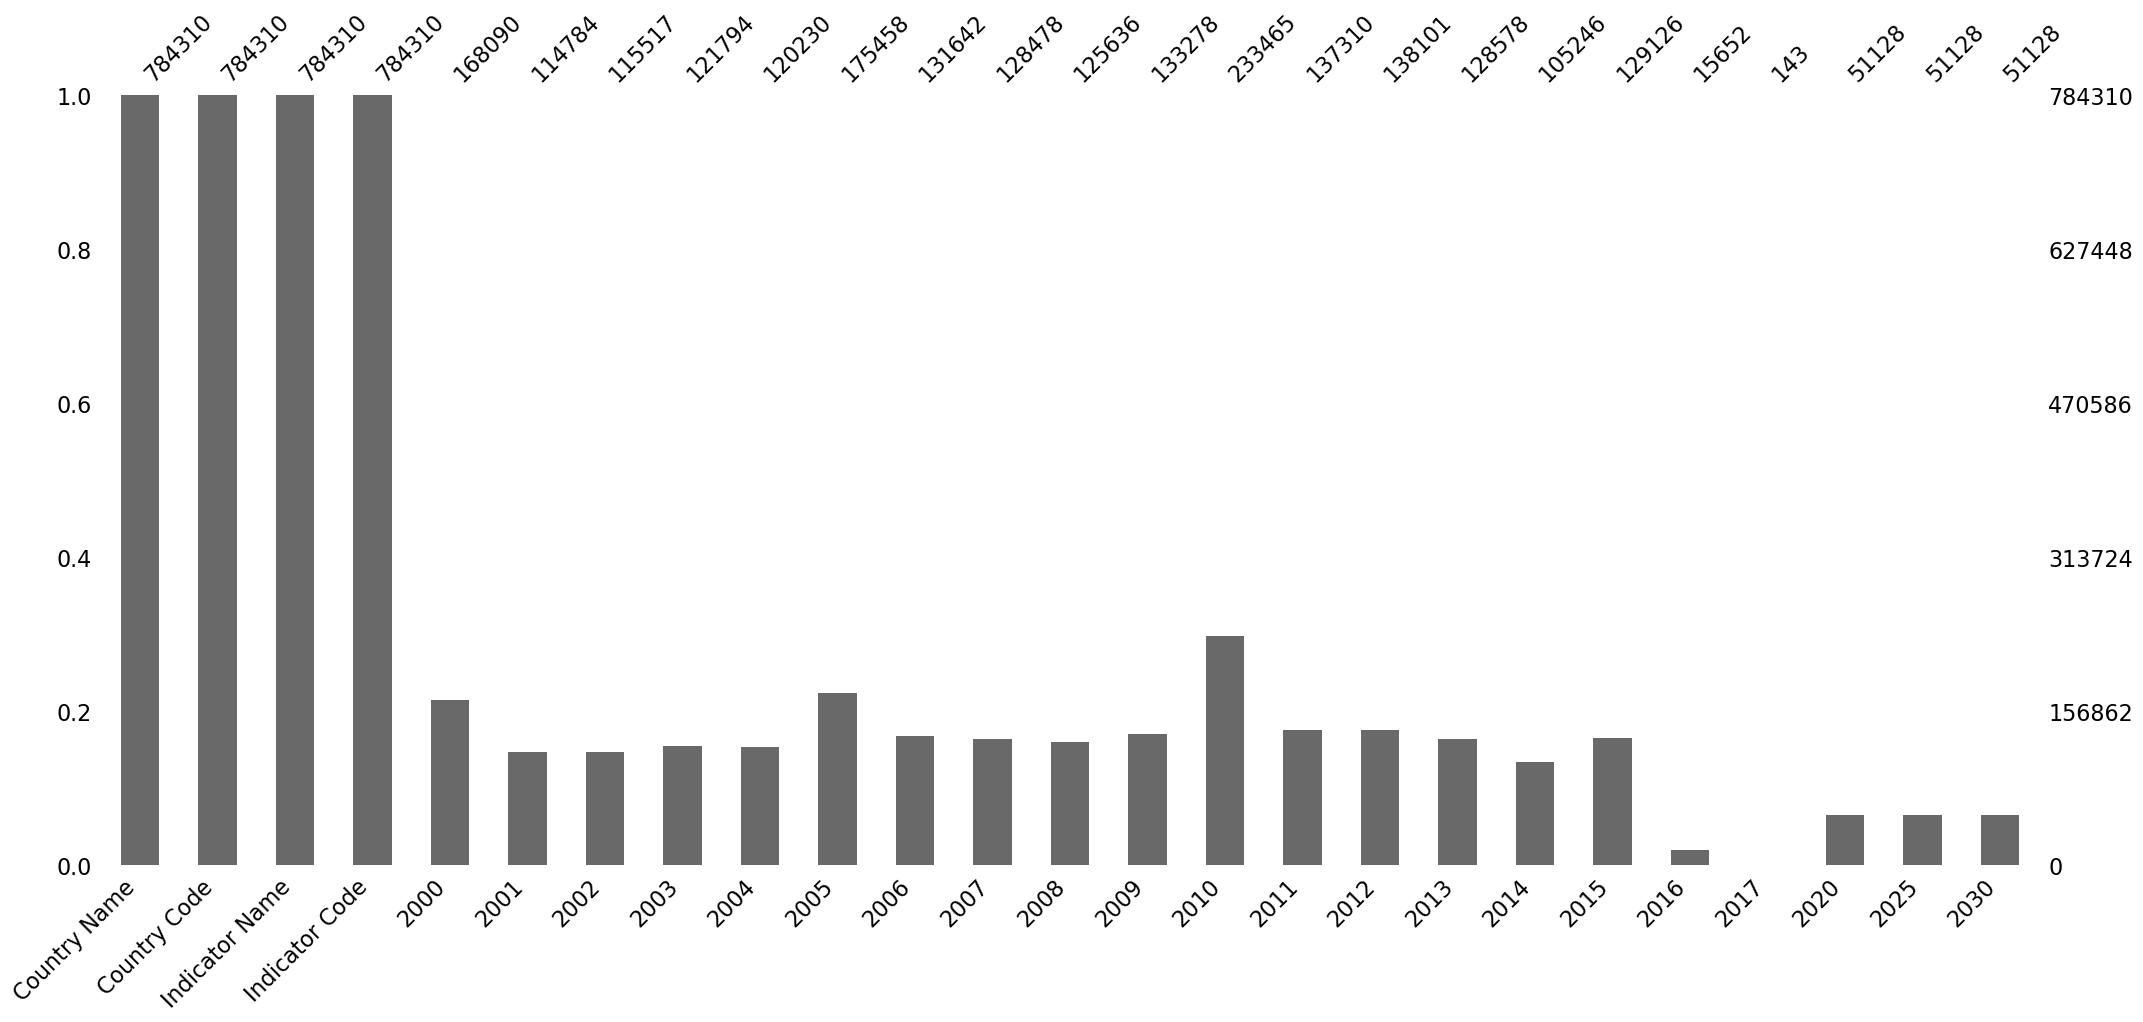

array(['Net enrolment rate, upper secondary, both sexes (%)'],
      dtype=object)

In [7]:
description(df_data_clean, "EdStatsData.csv");
df_data_clean[df_data_clean['Indicator Code'] == 'UIS.NER.3']['Indicator Name'].unique()

----------------------------------------------------------------------------------------------------------------------------
##### b. EdStatsCountry
Il s'agit de la table la plus simple à lire mais pas la moins détaillée. Ce sont les codes pays et ou de régions. Chaque pays a des caractéristiques qui lui sont propres.  

Là aussi, les variables étant nombreuses, je n'entrerai pas dans les détails. De plus, comme dit précédemment, les variables sur cette table sont lisibles et compréhensibles.
- Country Code:  Code pays	
- Short Name : Nom court	
- Table Name : Nom réel simplifié 	
- Long Name : Nom officiel
- WB-2 code : Code alphanumérique
- Currency Unit	: Devises monétaire
Etc.

----------------------------------------
EdStatsCountry.csv
----------------------------------------


,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005


----------------------------------------
Affichage du nombre de lignes et de colonnes
----------------------------------------


(214, 28)

----------------------------------------
Affichage des doublons
----------------------------------------
0
----------------------------------------
Affichage des valeurs manquantes
----------------------------------------


Country Code                                           0
Short Name                                             0
Table Name                                             0
Long Name                                              0
2-alpha code                                           3
Currency Unit                                          0
Special Notes                                         94
Region                                                 0
Income Group                                           0
WB-2 code                                              1
National accounts base year                            9
SNA price valuation                                   17
Lending category                                      70
System of National Accounts                            0
PPP survey year                                       69
Balance of Payments Manual in use                     33
External debt Reporting status                        90
System of trade                

... (52 outputs left out)

-----Analyse de la colonne : Latest agricultural census-----


Latest agricultural census
2010    36
2007    16
2013    13
Name: count, dtype: int64

-----Analyse de la colonne : Latest water withdrawal data-----


Latest water withdrawal data
2000    40
2005    40
2007    18
Name: count, dtype: int64

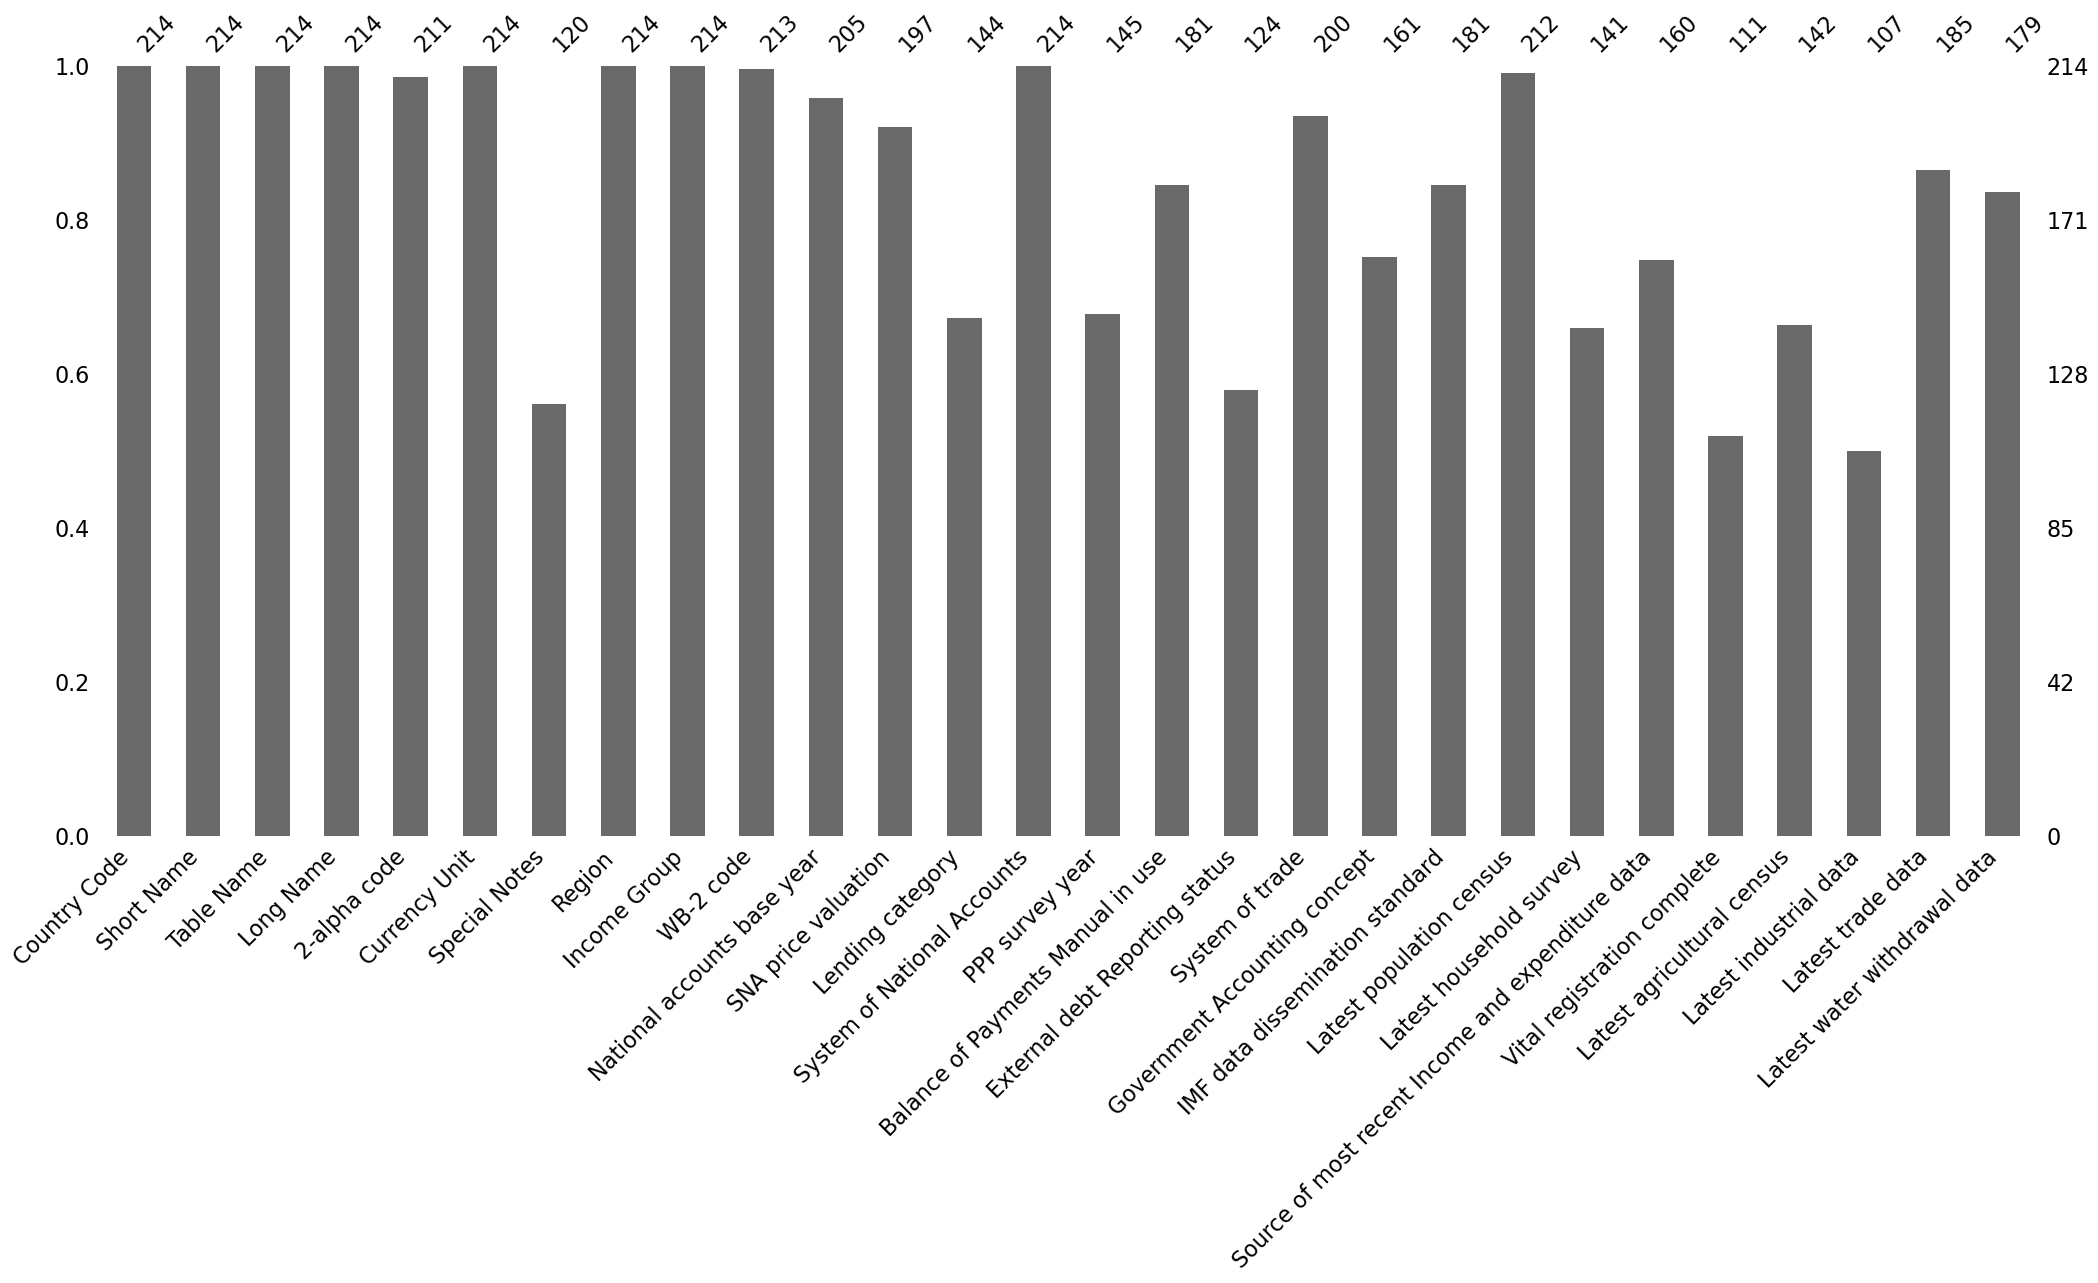

In [8]:
description(df_country_clean, "EdStatsCountry.csv");

----------------------------------------------------------------------------------------------------------------------------
##### c. EdStatsSeries
C'est la table des codes séries. Il y a 32 colonnes et 3665 lignes. Cette colonne liste la pluralité des codes séries et leur combinaison, c'est-à-dire toutes les combinaisons d'options que l'on puisse avoir pour une observation (ligne) et aussi que l'on puisse sélectionner sur le frontend.  

Je ne ferai pas la liste des variables car elles sont nombreuses, mais voici une brève description : 
- SeriesCode : Elle est unique.  Elle est composée d'une combinaison d'abréviations qui renvoient à un élément ou une définition (Primaire, secondaire, âge, etc.).  
- Topic : "Attainment"(niveau d'études) C'est une catégorie de filtre. Il y en a d'autres, comme on peut le voir grâce à la commande **".unique.tolist"**. Comme on peut le constater cela fait bien référence à des catégories.

----------------------------------------
EdStatsSeries.csv
----------------------------------------


,Series Code,Topic,Indicator Name,Short definition,Long definition,Source
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15-19 with...,Percentage of female population age 15-19 with...,Robert J. Barro and Jong-Wha Lee: http://www.b...
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 ...,Percentage of population age 15-19 with no edu...,Percentage of population age 15-19 with no edu...,Robert J. Barro and Jong-Wha Lee: http://www.b...
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15+ with n...,Percentage of female population age 15+ with n...,Robert J. Barro and Jong-Wha Lee: http://www.b...


----------------------------------------
Affichage du nombre de lignes et de colonnes
----------------------------------------


(2968, 6)

----------------------------------------
Affichage des doublons
----------------------------------------
0
----------------------------------------
Affichage des valeurs manquantes
----------------------------------------


Series Code            0
Topic                  0
Indicator Name         0
Short definition    1047
Long definition        0
Source                 0
dtype: int64

... (12 outputs left out)

-----Analyse de la colonne : Long definition-----


Long definition
Percentage of students who were unable to read a single word of text on the oral reading fluency subtask. The oral reading fluency/paragraph reading subtask examines students' ability to read a narrative or informational text with accuracy, with little effort, and at a sufficient rate. Consult the EdData website and the specific country report for more information: www.eddataglobal.org.                                                                                                                                                                                      51
Share of students who scored 80 percent or higher on the reading comprehension assessment. The reading comprehension subtask follows the oral reading fluency subtask; students are required to respond to literal and inferential questions about the oral reading fluency subtask text they have just read. The questions are read aloud to the student by the assessor. Users are discouraged from using these data to 

-----Analyse de la colonne : Source-----


Source
UNESCO Institute for Statistics                                                 839
Early Grade Reading Assessment (EGRA): https://www.eddataglobal.org/reading/    403
Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/                      360
Name: count, dtype: int64

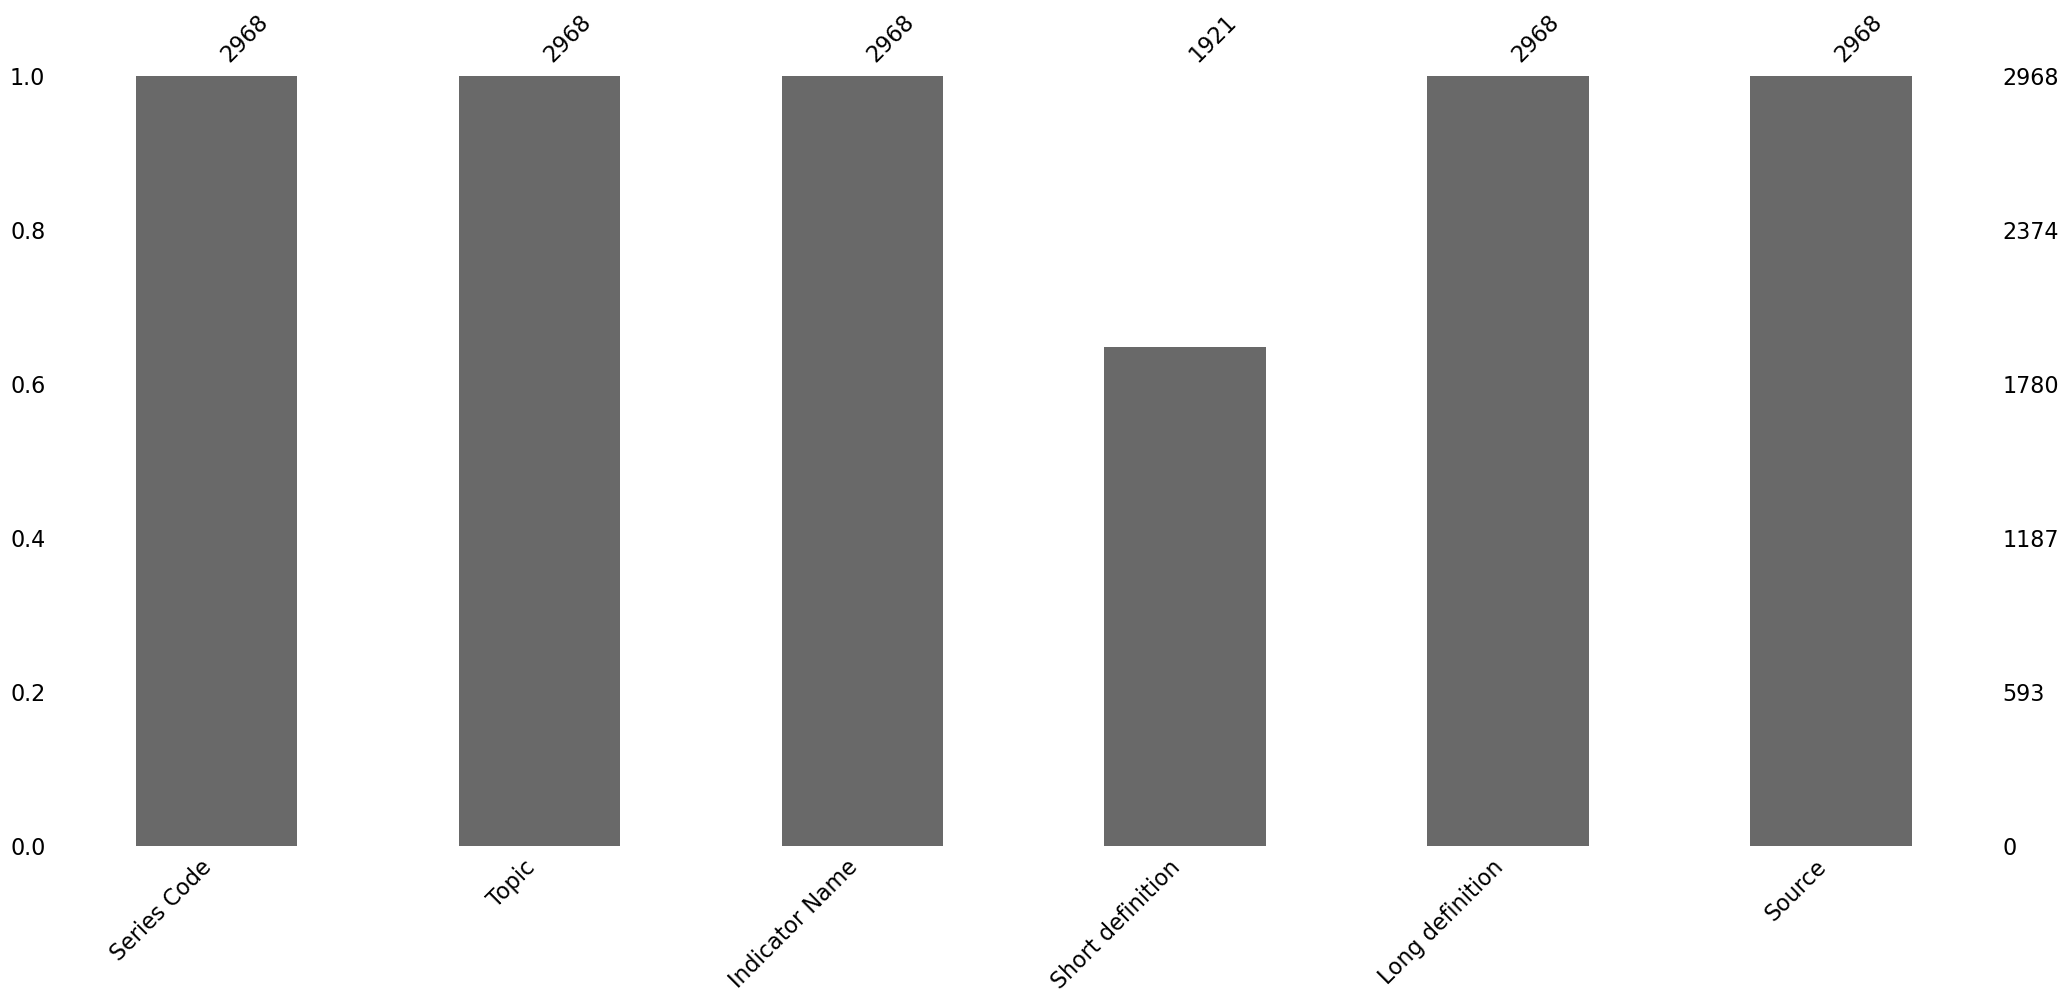

,Series Code,Indicator Name
2313,SE.SEC.ENRR.UP,"Gross enrolment ratio, upper secondary, both s..."
2314,SE.SEC.ENRR.UP.FE,"Gross enrolment ratio, upper secondary, female..."
2315,SE.SEC.ENRR.UP.MA,"Gross enrolment ratio, upper secondary, male (%)"
2825,UIS.E.3,"Enrolment in upper secondary education, both s..."
2826,UIS.E.3.F,"Enrolment in upper secondary education, female..."
2827,UIS.E.3.GPV,"Enrolment in upper secondary general, both sex..."
2828,UIS.E.3.GPV.F,"Enrolment in upper secondary general, female (..."
2829,UIS.E.3.PR,"Enrolment in upper secondary education, privat..."
2830,UIS.E.3.PR.F,"Enrolment in upper secondary education, privat..."
2831,UIS.E.3.PU,"Enrolment in upper secondary education, public..."


In [9]:
description(df_series_clean, "EdStatsSeries.csv");
df_series_clean[df_series_clean['Indicator Name'].str.contains('upper secondary', case=False)][['Series Code', 'Indicator Name']].drop_duplicates()
mask = (
    df_series_clean['Indicator Name'].str.contains('upper secondary', case=False) &
    df_series_clean['Indicator Name'].str.contains('enroll|enrol|attendance|NER|GER', case=False)
)

df_series_clean[mask][['Series Code', 'Indicator Name']].drop_duplicates()

----------------------------------------------------------------------------------------------------------------------------
##### c. EdStatsCountry-series 
On est dans la même typologie de table que : EdStatsFootNote, c'est à dire une table de métadonnée qui tient informé sur des clés uniques de combinaisons de clefs limitées de chaque pays. Plus de 600 lignes avec 4 colonnes.
- *CountryCode* : Le code pays, donc la clef pays
- *SeriesCode* : Le code série
- *Description* : Description sur les sources de données

----------------------------------------
EdStatsCountry-Series.csv
----------------------------------------


,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005


----------------------------------------
Affichage du nombre de lignes et de colonnes
----------------------------------------


(214, 28)

----------------------------------------
Affichage des doublons
----------------------------------------
0
----------------------------------------
Affichage des valeurs manquantes
----------------------------------------


Country Code                                           0
Short Name                                             0
Table Name                                             0
Long Name                                              0
2-alpha code                                           3
Currency Unit                                          0
Special Notes                                         94
Region                                                 0
Income Group                                           0
WB-2 code                                              1
National accounts base year                            9
SNA price valuation                                   17
Lending category                                      70
System of National Accounts                            0
PPP survey year                                       69
Balance of Payments Manual in use                     33
External debt Reporting status                        90
System of trade                

... (52 outputs left out)

-----Analyse de la colonne : Latest agricultural census-----


Latest agricultural census
2010    36
2007    16
2013    13
Name: count, dtype: int64

-----Analyse de la colonne : Latest water withdrawal data-----


Latest water withdrawal data
2000    40
2005    40
2007    18
Name: count, dtype: int64

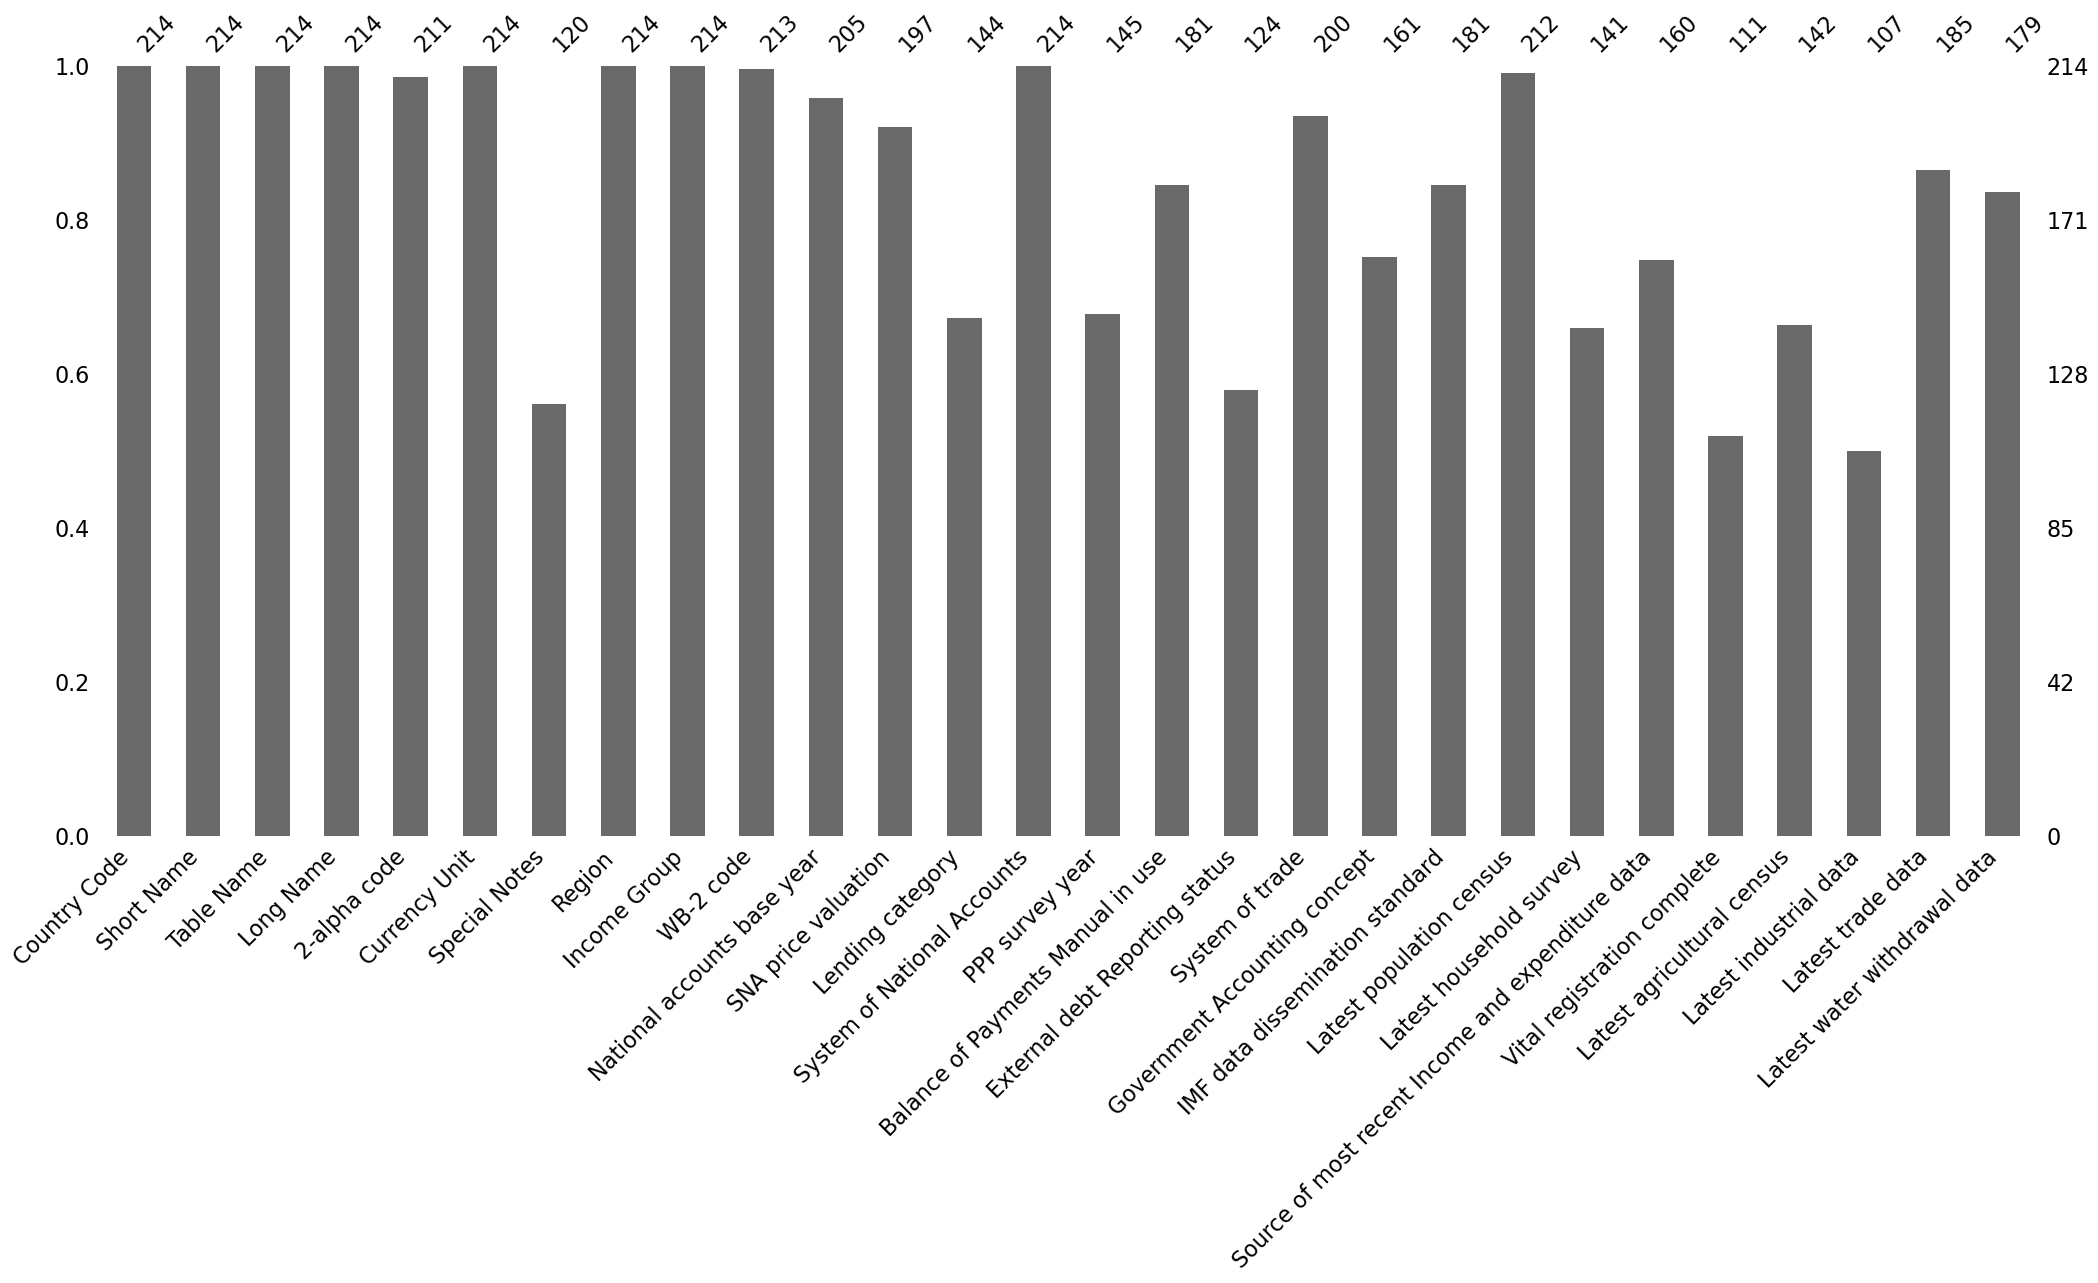

In [10]:
description(df_country_clean, "EdStatsCountry-Series.csv");

----------------------------------------------------------------------------------------------------------------------------
##### a. EdStatsFootNote
Le fichier comporte plus de 640k lignes, 5 variables.   
Les variables  intéressantes ici sont :  
- *CountryCode* : le code pays permet la liaison pays
- *SeriesCode* : Permet la liaison avec les codes séries
- *Year* : L'année
- *Description* : Permet de savoir et connaître les sources de données ou de changements

----------------------------------------
EdStatsFootNote.csv
----------------------------------------


,CountryCode,SeriesCode,Year,DESCRIPTION
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.


----------------------------------------
Affichage du nombre de lignes et de colonnes
----------------------------------------


(643638, 4)

----------------------------------------
Affichage des doublons
----------------------------------------
0
----------------------------------------
Affichage des valeurs manquantes
----------------------------------------


CountryCode    0
SeriesCode     0
Year           0
DESCRIPTION    0
dtype: int64

... (8 outputs left out)

-----Analyse de la colonne : Year-----


Year
YR2004    27128
YR2005    25992
YR2002    25687
Name: count, dtype: int64

-----Analyse de la colonne : DESCRIPTION-----


DESCRIPTION
Country Data                                      191188
UNESCO Institute for Statistics (UIS) estimate    171527
Estimated                                         117155
Name: count, dtype: int64

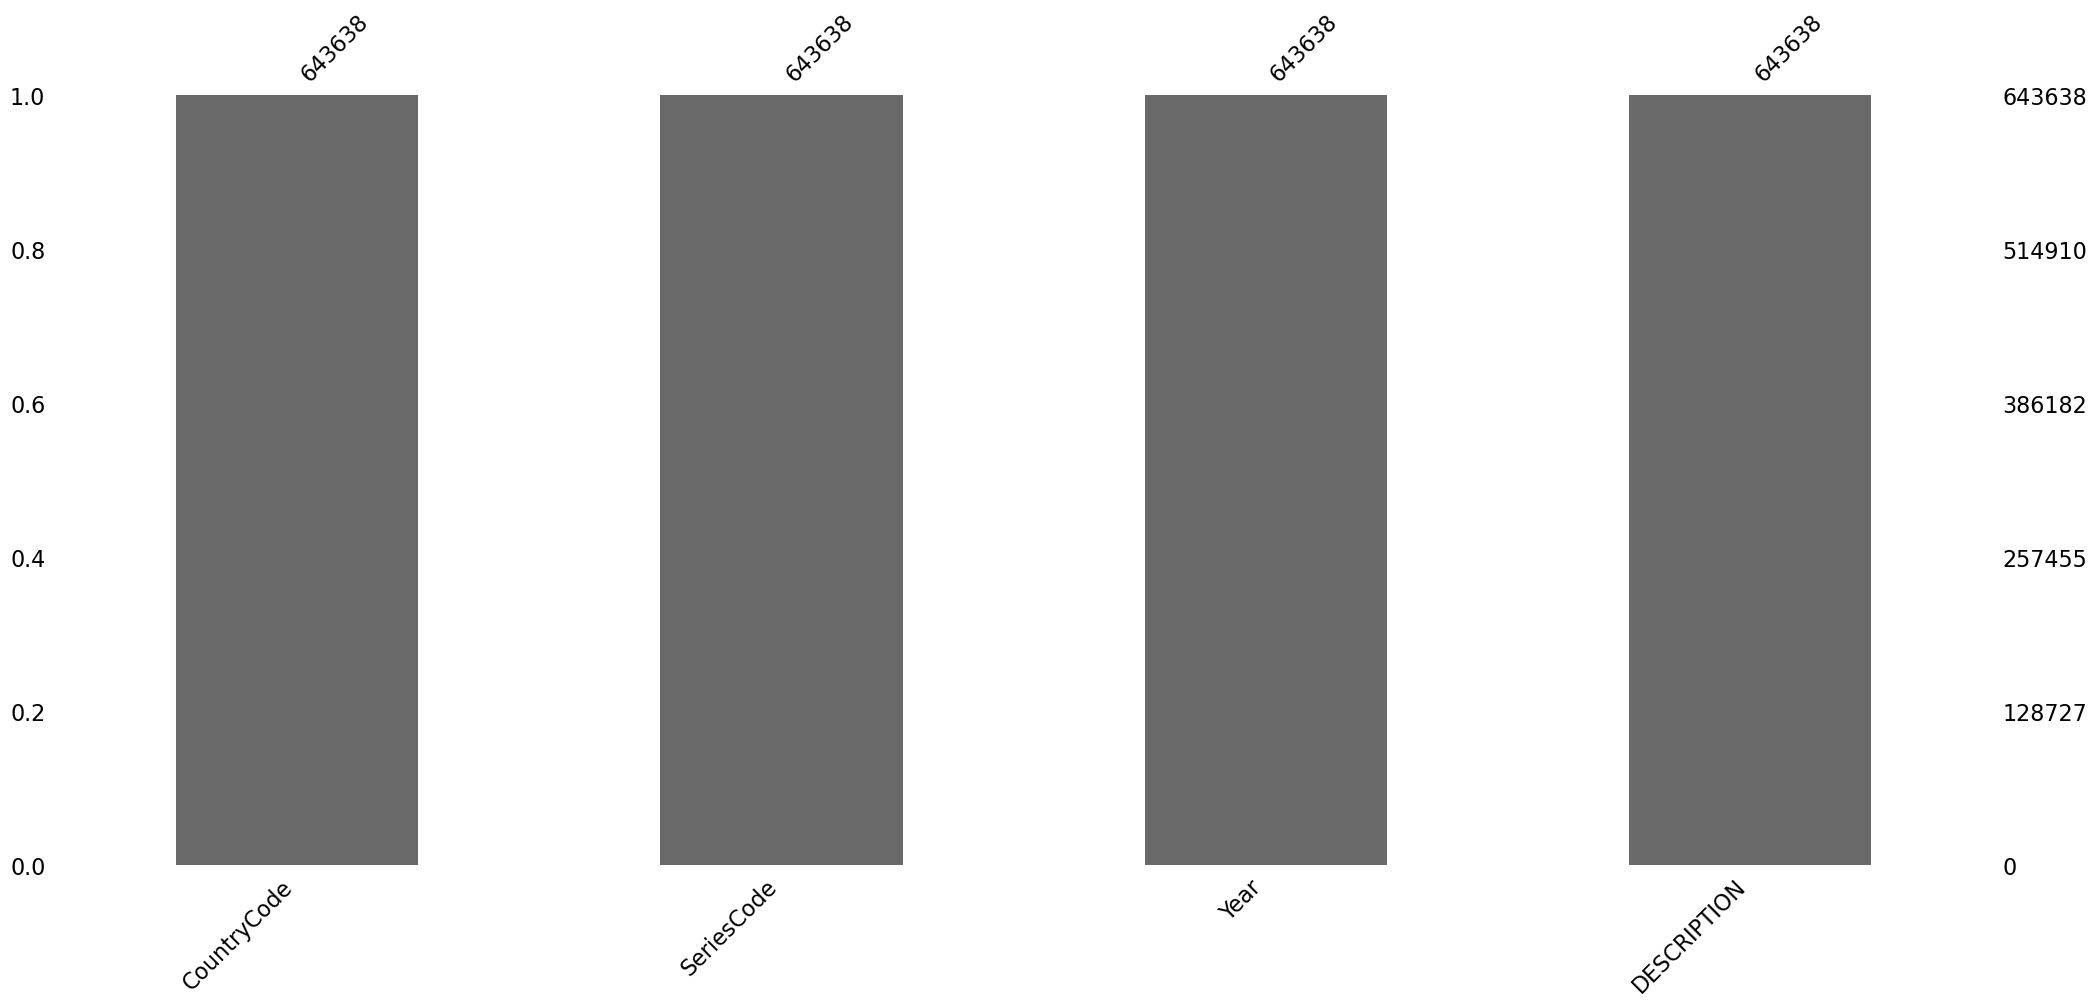

In [11]:
description(df_foot_clean, "EdStatsFootNote.csv");

## 2 - Reduction du périmètre

### 1. Les années et leur complétude
On calcule le nombre de valeurs renseignées pour chaque année.

In [12]:
proportion_valeur_annee = [yrs for yrs in df_data_clean.columns if yrs.isdigit()]
proportion_indicateurs_annee = df_data_clean[proportion_valeur_annee].notna().mean().mul(100).round(2)
proportion_indicateurs_annee = proportion_indicateurs_annee.sort_values(ascending=False)

On filtre les années ayant moins de 10% de données

In [13]:
# Filtre fes années
proportion_indicateurs_annee = proportion_indicateurs_annee[proportion_indicateurs_annee >= 10]
titre("Proportion de valeurs parmi les années préselectionnées")
print(proportion_indicateurs_annee)

----------------------------------------
Proportion de valeurs parmi les années préselectionnées
----------------------------------------
2010    29.77
2005    22.37
2000    21.43
2012    17.61
2011    17.51
2009    16.99
2006    16.78
2015    16.46
2013    16.39
2007    16.38
2008    16.02
2003    15.53
2004    15.33
2002    14.73
2001    14.64
2014    13.42
dtype: float64


### 2. Complétude des indicateurs : Top 20 en %
On agrège les indicateurs et on calcule le nombre de valeurs renseignées sans distinction avec groupby (cad sur toutes les années et tous les pays)

In [14]:
completude_indicateur = (
    df_data_clean
    .groupby(['Indicator Code', 'Indicator Name'])[proportion_valeur_annee]
    .apply(lambda x : x.notna().mean().mean())
    .sort_values(ascending=False)
    .mul(100)
    .round(2)
)

2.1 Je sélectionne certains paramètres de certains indicateurs pour les éliminer et ainsi réduire le df car ils ne seront pas utilisés: 0 à 14, female, male, primaire, etc...Pour plus de lisibilité

In [15]:
# Filtre reduction des indicateurs pour plus de lisibilité

completude_indicateur = completude_indicateur[
  ~completude_indicateur 
  .index
  .get_level_values('Indicator Name')
  .str.contains('primary|male|female|0014|Mortality', case = False, na = False)
]

titre("Complétude des indicateurs : Top 20")
display(completude_indicateur.head(20))

----------------------------------------
Complétude des indicateurs : Top 20
----------------------------------------


Indicator Code     Indicator Name                                                                             
SP.POP.TOTL        Population, total                                                                              80.57
SP.POP.GROW        Population growth (annual %)                                                                   80.55
UIS.THAGE.3.A.GPV  Official entrance age to upper secondary education (years)                                     76.28
NY.GDP.MKTP.CD     GDP at market prices (current US$)                                                             75.95
NY.GDP.PCAP.CD     GDP per capita (current US$)                                                                   75.95
SE.SEC.DURS        Theoretical duration of secondary education (years)                                            75.70
SE.SEC.DURS.LO     Theoretical duration of lower secondary education (years)                                      75.70
SE.SEC.AGES        Official entrance age to lower

### 3. Table de complétude des pays : Top 20 en %
On isole chaque indicateur et on calcule la moyenne individuelle de complétude pour toute la table sauf que le groupby est appliqué au pays (colonne "Country Name")

In [16]:
completude_pays = (
    df_data_clean
    .groupby(['Country Name'])[proportion_valeur_annee]
    .apply(lambda x : x.notna().mean().mean())
    .sort_values(ascending = False)
    .mul(100)
    .round(2)
)

titre("Completude par pays : Top 20")
display(completude_pays.head(20))


----------------------------------------
Completude par pays : Top 20
----------------------------------------


Country Name
Mexico             22.26
Bulgaria           22.24
Lithuania          21.98
Italy              21.80
Czech Republic     21.67
Colombia           21.66
Hungary            21.55
Finland            21.47
Sweden             21.34
Romania            21.31
Latvia             21.23
Kyrgyz Republic    21.17
Cyprus             21.11
Slovak Republic    20.95
Slovenia           20.86
El Salvador        20.66
Lao PDR            20.61
Switzerland        20.59
Malta              20.54
Estonia            20.51
dtype: float64

3.1 On affiche les stats pour déterminer un seuil raisonnable de filtration des pays à 10%


In [17]:
titre("Moyenne et medianne de completude des pays renseignés en %")
print(f"Moyenne : ",completude_pays.mean().round(2))
print(f"Médiane : ",completude_pays.median())

titre("Stats pays avant reduction")
display(completude_pays.describe().head(20).round(0))

# Filtre pays : Imposition d'un seuil de completude à 10% pour conserver les pays avec un minimum de renseignements
completude_pays = completude_pays[completude_pays >= 10]

titre("Stats pays après reduction")
display(completude_pays.describe().head(20).round(0))

pays_finaux = completude_pays.index.tolist()

----------------------------------------
Moyenne et medianne de completude des pays renseignés en %
----------------------------------------
Moyenne :  14.43
Médiane :  16.155
----------------------------------------
Stats pays avant reduction
----------------------------------------


count    214.0
mean      14.0
std        6.0
min        0.0
25%       12.0
50%       16.0
75%       19.0
max       22.0
dtype: float64

----------------------------------------
Stats pays après reduction
----------------------------------------


count    172.0
mean      17.0
std        3.0
min       10.0
25%       15.0
50%       17.0
75%       19.0
max       22.0
dtype: float64

### 4. Tableau croisé pour identifier les indicateurs les plus pertinents
 On croise les années avec les indicateurs, on met le nombre de pays en complétude pour chaque indicateur, ainsi on visualise le nombre de pays renseignés pour cet indicateur.

In [18]:
completude_annee_indicateur = (
    df_data_clean
    .drop_duplicates()
    .groupby(['Indicator Code','Indicator Name'])[proportion_valeur_annee]
    .apply(lambda x :((~x.isnull()).sum(axis=0)))
    .assign(moyenne = lambda x: x.mean(axis=1))
    .sort_values(by='moyenne', ascending = False)
    .round(0)
    .reset_index()
)

titre("Tableau croisé : completude des annees en fonction des indicateurs : Top 15")
display(completude_annee_indicateur.head(15))

----------------------------------------
Tableau croisé : completude des annees en fonction des indicateurs : Top 15
----------------------------------------


,Indicator Code,Indicator Name,2000,2001,2002,2003,2004,2005,2006,2007,...,2012,2013,2014,2015,2016,2017,2020,2025,2030,moyenne
0,SP.POP.TOTL,"Population, total",214,214,214,214,214,214,214,214,...,213,213,209,209,209,0,0,0,0,172.0
1,SP.POP.GROW,Population growth (annual %),214,214,214,214,214,214,214,214,...,213,213,209,209,209,0,0,0,0,172.0
2,SE.PRM.DURS,Theoretical duration of primary education (years),205,205,205,205,205,205,205,205,...,205,205,205,205,175,0,0,0,0,165.0
3,SE.PRM.AGES,Official entrance age to primary education (ye...,205,205,205,205,205,205,205,205,...,205,205,205,205,175,0,0,0,0,165.0
4,UIS.THAGE.0,Official entrance age to pre-primary education...,202,202,202,202,202,202,202,202,...,202,202,200,200,201,0,0,0,0,163.0
5,UIS.THAGE.3.A.GPV,Official entrance age to upper secondary educa...,202,202,202,202,202,202,202,202,...,201,202,201,200,201,0,0,0,0,163.0
6,NY.GDP.MKTP.CD,GDP at market prices (current US$),199,199,203,203,204,204,205,204,...,199,200,197,196,189,0,0,0,0,163.0
7,NY.GDP.PCAP.CD,GDP per capita (current US$),199,199,203,203,204,204,205,204,...,199,200,197,196,189,0,0,0,0,163.0
8,UIS.THDUR.0,Theoretical duration of pre-primary education ...,202,202,202,202,202,202,202,202,...,202,202,202,202,172,0,0,0,0,162.0
9,SE.SEC.DURS,Theoretical duration of secondary education (y...,202,202,202,202,202,202,202,202,...,201,202,202,202,172,0,0,0,0,162.0


### 4.1 Indicateurs finaux
Je crée ma liste d'indicateurs finaux que je vais utiliser.  Une à partir des indicateurs les mieux renseignés ici, donc issue de l'approche data, et l'autre de la sélection issue de l'approche métier que j'ai retenue.

In [19]:
# Ils sont plus qualitatf donc probalement moins renseignés

indicators_approche_metier = [
    # Lycée
    'UIS.NER.3',
    'SE.SEC.ENRR',         # Taux d'inscription au lycée (hors âge officiel)
    'SE.SEC.NENR',         # Taux d'inscription au lycée (âge officiel) = ratio avec le precedent, plus il est elevé plus des personnes cherche une alternative
    # Université
    'SP.TER.TOTL.IN',      # Population d'âge officiel pour le tertiaire =  taille du marché total
    'SE.TER.ENRL',         # Nombre d'inscrits dans le tertiaire = marché déjà capté
    'SE.TER.ENRR',         # Taux brut d'inscription au tertiaire 5 ans après le lycée (%)
    # Dépenses éducation
    'SE.XPD.TOTL.GD.ZS',   # Dépenses éducation en % du PIB = plus structurel si il est bas systeme marche equilibre si eleve corrobore la these budget
    'SE.XPD.TOTL.GB.ZS',   # Dépenses éducation en % du budget état = Correctif si elevé = lacunaire place a prendre
    # Alphabétisation
    'SE.ADT.1524.LT.ZS',   # Taux d'alphabétisation jeunes 15-24 = Condition de faisabilité
]

# Renseignés à plus de 70 %
indicators_approche_data = [
    # Lycée
    'SP.SEC.UTOT.IN',     # Population d'âge officiel lycée = marché officiel de la campagne de ciblage Lycée = Indicateur principal lycée
    # Population
    'SP.POP.GROW',        # Croissance démographique annuelle permet d'évaluer la croissance  mediane lisser sur 10 ans donc assez revelateur
    # Économie
    'NY.GDP.PCAP.PP.KD',  # PIB par habitant PPA (dollars constants 2011) = en %, condition de revenus individuel (%)
    # Internet
    'IT.NET.USER.P2',     # Internautes pour 100 habitants = conditions de  moyens (%)
]

# On ajoutera après le piot des colonnes calculées spour Indicateurs_calcule =
# tx_hors_parcours_tertiaire'(SP.TER.TOTL.IN - SE.TER.ENRL) / SP.TER.TOTL.IN * 100' # tertiare marché non capté = potentiel plausible pour Academy en %
# tx_hors_parcours_lycée'(SP.SEC.UTOT.IN - SE.SEC.NENR) / SP.SEC.UTOT.IN * 100' # lycée marché non capté = les hors parcours scolaire, potentiel plausible pour Academy

indicateurs_finaux = completude_indicateur[
    completude_indicateur
    .index
    .get_level_values('Indicator Code')
    .isin(indicators_approche_metier + indicators_approche_data)
    .tolist() 
].index.get_level_values('Indicator Code').tolist()


### 5. Création du dataframe final pour visualisation

In [20]:
# On reprends le dataframe filtré par nos deux listes
df_data_final = df_data_clean[
    (df_data_clean['Indicator Code'].isin(indicateurs_finaux)) &
    (df_data_clean['Country Name'].isin(pays_finaux))
]

# On créer la mediane de toute les années, la dimension temporelle ne nous intéresse pas ici nous cherchons à comparer des pays 
# Nous travaillons sur des masse globales je fait la mediane de toutes le années pour selectionner les pays potentielc'est le previsionnel qui permettra d'identifier 
df_data_final[proportion_valeur_annee].median(axis = 1).round(2)

# On crée la colonne de cette mediane
df_data_final = df_data_final.assign(
    mediane = lambda x:x[proportion_valeur_annee].median(axis = 1)
)

# Creation du dataframe pivoté très lisible avec une seule valeur representant toute les années 
df_data_pivot = df_data_final.pivot(
    index = 'Country Name',
    columns = 'Indicator Code',
    values = 'mediane'
)

# On ajoute nos 2 colonnes à calculer
df_data_pivot = df_data_pivot.assign(
    taux_hors_parcours_tertiaire = lambda x: (100 - x['SE.TER.ENRR']).clip(lower=0),
    taux_hors_parcours_lycee = lambda x: (100 - x['UIS.NER.3'])
)

# Evalue le nombre de nan pour evaluer visuelement les biais les résultat montre que c'est tres acceptable 
(df_data_pivot.isnull().sum().round(0) / len(df_data_pivot) * 100).round()

# Pour eviter les valeurs extremes et evacuer les nan du dataframe on impute la mediane des indicateurs au nan.
# 23% de nan maximum interferons peu sur les correlations
df_data_pivot = df_data_pivot.fillna(df_data_pivot.median())

display(df_data_pivot.round(2).head(20))


Indicator Code,IT.NET.USER.P2,NY.GDP.PCAP.PP.KD,SE.ADT.1524.LT.ZS,SE.SEC.ENRR,SE.SEC.NENR,SE.TER.ENRL,SE.TER.ENRR,SE.XPD.TOTL.GB.ZS,SE.XPD.TOTL.GD.ZS,SP.POP.GROW,SP.SEC.UTOT.IN,SP.TER.TOTL.IN,UIS.NER.3,taux_hors_parcours_tertiaire,taux_hors_parcours_lycee
Country Name,,,,,,,,,,,,,,,
Albania,23.86,9153.73,99.03,82.46,84.02,88734.5,31.37,10.70,3.24,-0.42,240167.0,274635.0,68.87,68.63,31.13
Algeria,10.18,12647.54,91.78,76.98,76.87,1022916.5,26.65,11.43,4.35,1.62,2290183.5,3758584.5,54.15,73.35,45.85
Argentina,28.11,17900.71,99.11,96.57,79.45,2208291.0,66.83,15.88,4.83,1.05,2054973.0,3342870.5,56.58,33.17,43.42
Armenia,6.21,6702.85,99.83,91.06,87.94,115341.0,43.61,12.59,2.74,-0.55,122462.0,285816.5,75.14,56.39,24.86
Aruba,52.00,35973.78,99.08,97.25,75.96,1899.0,30.28,20.79,4.92,0.59,4486.0,6471.0,51.05,69.72,48.95
Australia,75.12,41207.13,97.08,137.56,86.23,1083715.0,73.39,13.42,4.91,1.39,586776.0,1513658.5,72.54,26.61,27.46
Austria,72.87,43384.59,97.08,99.39,76.87,274730.0,56.69,10.48,5.51,0.49,384678.0,509464.0,54.15,43.31,45.85
Azerbaijan,27.40,14364.99,99.95,84.35,76.87,181615.0,19.72,9.18,2.78,1.16,355302.5,882543.5,73.38,80.28,26.62
"Bahamas, The",31.54,24350.38,97.08,92.13,84.02,175139.0,24.51,18.92,2.85,1.75,18196.0,30308.0,70.05,75.49,29.95


# PARTIE IV - Visualisation
## 1 - Production des heatmap
On utilise dans un premier temps des heatmap pour identifier les indiateurs etant très corrélés.

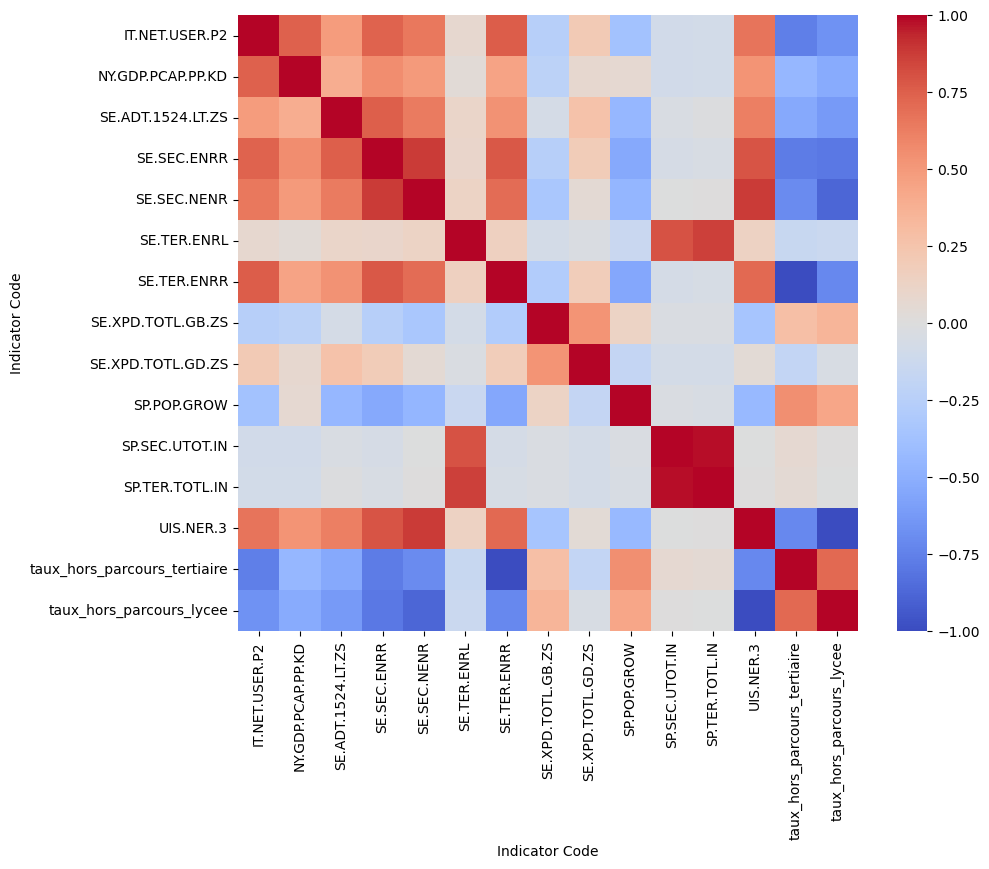

In [21]:
# On initialise une variable de la correlation de pearson sur notre dataframe df_data_pivot
df_corr_pearson = df_data_pivot.corr(method = 'pearson')

# On l'affiche sur matplotlib
plt.figure(figsize =(10,8))
sns.heatmap(
    df_corr_pearson, 
    annot = False, 
    cmap = 'coolwarm'
)
plt.show()

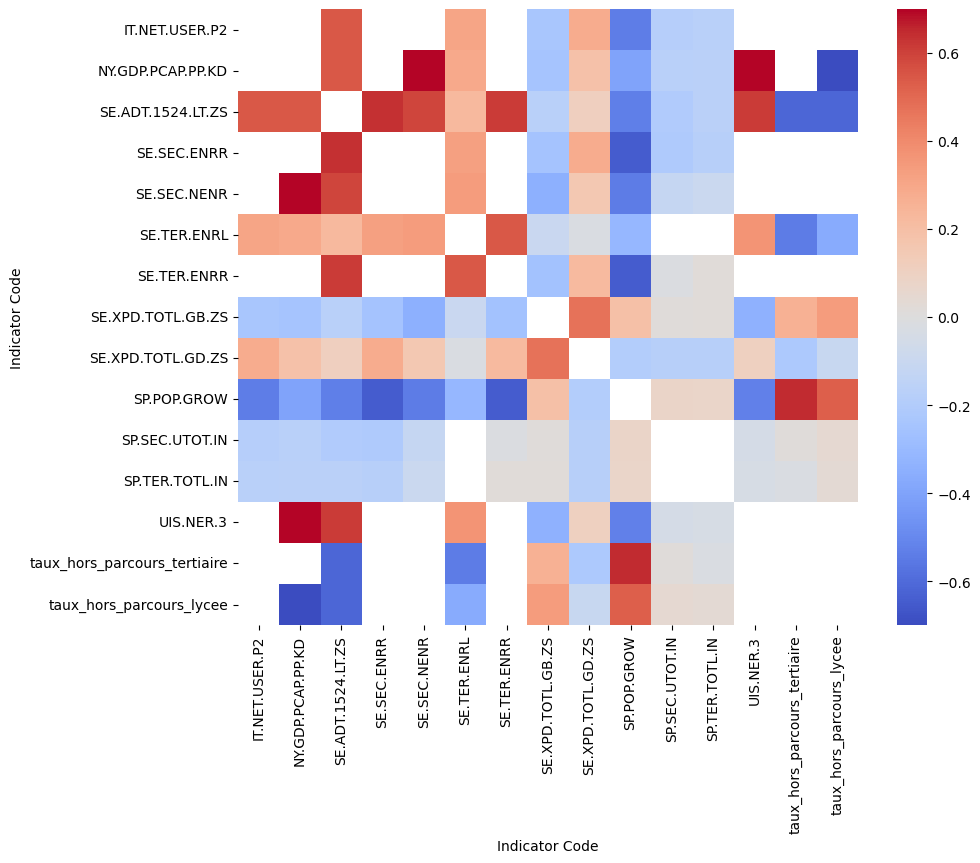

In [22]:
# Avec spearman
df_corr_spearman = df_data_pivot.corr(method = 'spearman')

# On visualise la correlation sur une heatmap(carte de chaleur) pour evaluer les indicateurs fortement corrélés, 
# cat ils sont redondant ils ne seront pas revelateurs.
# On etabli un seuil pour pouvoir retirer les corelations fortes
seuil = 0.70
mask = df_corr_spearman.abs() >= seuil
plt.figure(figsize =(10,8))
sns.heatmap(
    df_corr_spearman, 
    mask = mask,
    annot = False, 
    cmap = 'coolwarm'
)

plt.show()

je selectionne les idicateurs qui répondent au filtre. À partir de là je crée une liste des indicateurs à evacuer.

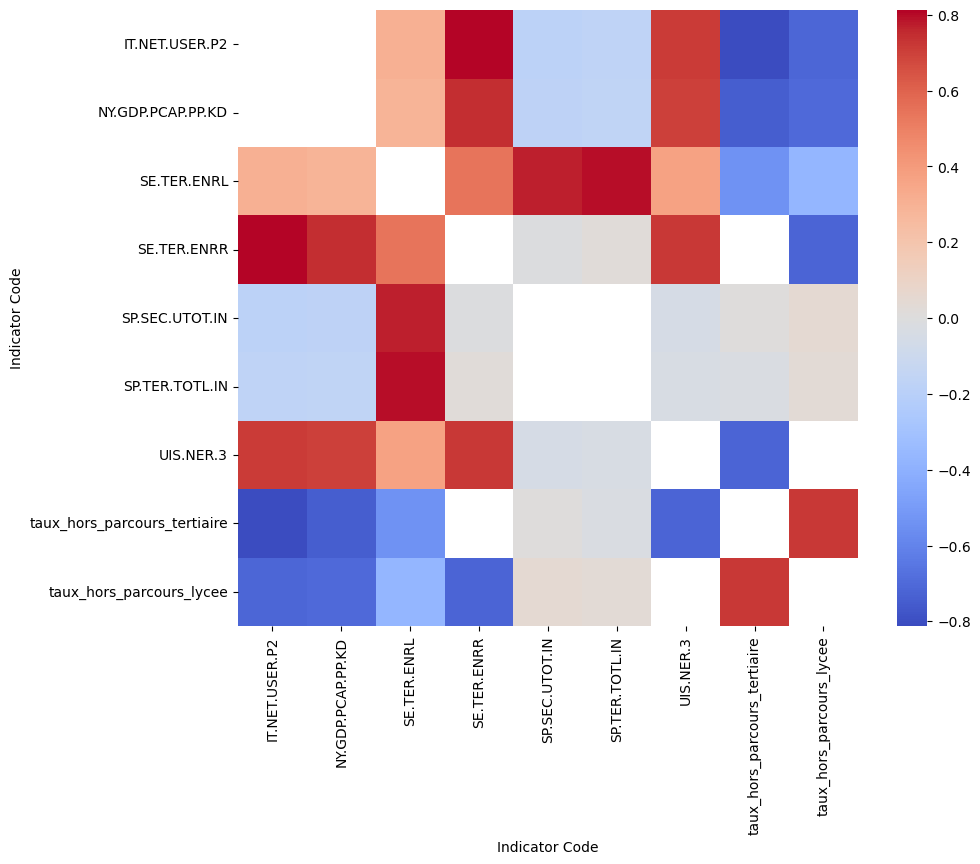

In [23]:
# Liste des indicateurs à suprimer
corr_sup = [
    'SE.ADT.1524.LT.ZS',   # Taux d'alphabétisation jeunes 15-24 = Condition de faisabilité
    'SE.XPD.TOTL.GD.ZS',   # Dépenses éducation en % du PIB = plus structurel si il est bas systeme marche equilibre si eleve corrobore la these budget
    'SE.XPD.TOTL.GB.ZS',   # Dépenses éducation en % du budget état = Correctif si elevé = lacunaire place a prendre
    'SP.POP.GROW',         # Croissance démographique annuelle permet d'évaluer la croissance  mediane lisser sur 10 ans donc assez revelateur
    'SE.SEC.ENRR',         # Taux d'inscription au lycée (hors âge officiel)
    'SE.SEC.NENR',         # Taux d'inscription au lycée (âge officiel) = ratio avec le precedent, plus il est elevé plus des personnes cherche une alternative
]

df_data_pivot = df_data_pivot.drop(columns = corr_sup)

df_corr_pearson = df_data_pivot.corr(method = 'pearson')

df_corr_spearman = df_data_pivot.corr(method = 'spearman')

seuil = 0.85
mask = df_corr_spearman.abs() >= seuil
plt.figure(figsize =(10,8))
sns.heatmap(
    df_corr_spearman, 
    mask = mask,
    annot = False, 
    cmap = 'coolwarm'
)
plt.show()

## 2 - Production des statistiques individuelle par indicateurs
On visualise et descris statistiquement un indicateurs, on realisera ensuite une fonction pour l'appliquer à tous les indicateurs.

count    172.00
mean      31.39
std       24.85
min        0.48
25%        9.65
50%       24.51
75%       50.27
max       92.88
Name: SE.TER.ENRR, dtype: float64

<Axes: xlabel='SE.TER.ENRR', ylabel='Count'>

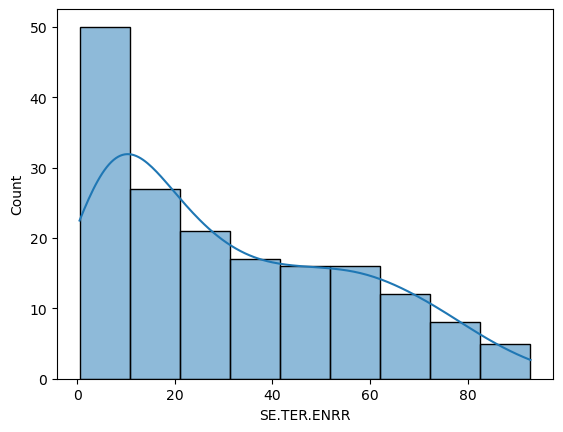

In [24]:
display(df_data_pivot['SE.TER.ENRR'].describe().round(2))
sns.histplot(df_data_pivot['SE.TER.ENRR'], kde = True)

Permet ici d'afficher les definitions longues pour voir à quoi les indicateurs renvoient, avec sa traduction en francais.

In [25]:
pd.set_option('display.max_colwidth', None)
display(df_series_clean[
    df_series_clean['Series Code'].isin(df_data_pivot.columns.tolist())
][['Series Code', 'Long definition']])

,Series Code,Long definition
611,IT.NET.USER.P2,"Internet users are individuals who have used the Internet (from any location) in the last 3 months. The Internet can be used via a computer, mobile phone, personal digital assistant, games machine, digital TV etc."
1665,NY.GDP.PCAP.PP.KD,GDP per capita based on purchasing power parity (PPP). PPP GDP is gross domestic product converted to international dollars using purchasing power parity rates. An international dollar has the same purchasing power over GDP as the U.S. dollar has in the United States. GDP at purchaser's prices is the sum of gross value added by all resident producers in the economy plus any product taxes and minus any subsidies not included in the value of the products. It is calculated without making deductions for depreciation of fabricated assets or for depletion and degradation of natural resources. Data are in constant 2011 international dollars.
2332,SE.TER.ENRL,The total number of students enrolled at public and private tertiary education institutions.
2335,SE.TER.ENRR,"Total enrollment in tertiary education (ISCED 5 to 8), regardless of age, expressed as a percentage of the total population of the five-year age group following on from secondary school leaving."
2611,SP.SEC.UTOT.IN,Population of the age-group theoretically corresponding to upper secondary education as indicated by theoretical entrance age and duration.
2614,SP.TER.TOTL.IN,Population of the age-group theoretically corresponding to tertiary education as indicated by theoretical entrance age and duration.
3218,UIS.NER.3,"Total number of students in the theoretical age group for upper secondary education enrolled in that level, expressed as a percentage of the total population in that age group. Divide the number of students enrolled who are of the official age group for upper secondary education by the population for the same age group and multiply the result by 100. NER at each level of education should be based on enrolment of the relevant age group in all types of schools and education institutions, including public, private and all other institutions that provide organized educational programmes."


### ***Indicateurs World Bank — Sélection finale projet Academy, détails des indicateurs***

| # | Code | Indicateur | Définition |
|---|------|-----------|-----------|
| 1 | `IT.NET.USER.P2` | **Utilisateurs d'Internet** | Personnes ayant utilisé Internet (depuis n'importe quel endroit) au cours des 3 derniers mois. L'accès peut se faire via un ordinateur, téléphone mobile, assistant numérique personnel, console de jeux, télévision numérique, etc. |
| 2 | `NY.GDP.PCAP.PP.KD` | **PIB par habitant en PPA ($ constants 2011)** | PIB par habitant basé sur la parité de pouvoir d'achat (PPA). Converti en dollars internationaux constants de 2011. Inclut la valeur ajoutée de tous les producteurs résidents, plus les taxes sur les produits, moins les subventions. Ne tient pas compte de la dépréciation des actifs ni de l'épuisement des ressources naturelles. |
| 3 | `SE.TER.ENRL` | **Effectifs dans le supérieur (nombre absolu)** | Nombre total d'étudiants inscrits dans les établissements d'enseignement supérieur publics et privés. |
| 4 | `SE.TER.ENRR` | **Taux brut de scolarisation — Supérieur (%)** | Inscriptions totales dans le supérieur (CITE 5 à 8), quel que soit l'âge, exprimées en % de la population du groupe d'âge des 5 ans suivant la fin du secondaire. |
| 5 | `SP.SEC.UTOT.IN` | **Population en âge du lycée** | Population du groupe d'âge correspondant théoriquement au second cycle du secondaire, selon l'âge d'entrée théorique et la durée des études. |
| 6 | `SP.TER.TOTL.IN` | **Population en âge du supérieur** | Population du groupe d'âge correspondant théoriquement à l'enseignement supérieur, selon l'âge d'entrée théorique et la durée des études. |
| 7 | `UIS.NER.3` | **Taux net de scolarisation — Lycée (%)** | Nombre d'élèves en âge officiel du lycée inscrits à ce niveau, exprimé en % de la population totale de ce groupe d'âge. Basé sur les inscriptions dans tous types d'établissements (publics, privés, etc.). |

Réalisatioin de la fonction de visualisation individuelle s'appliquant à tous les indicateurs. 

----------------------------------------
Internet users (per 100 people)
----------------------------------------


count    172.00
mean      27.96
std       26.09
min        0.22
25%        5.95
50%       21.38
75%       44.26
max       91.00
Name: IT.NET.USER.P2, dtype: float64

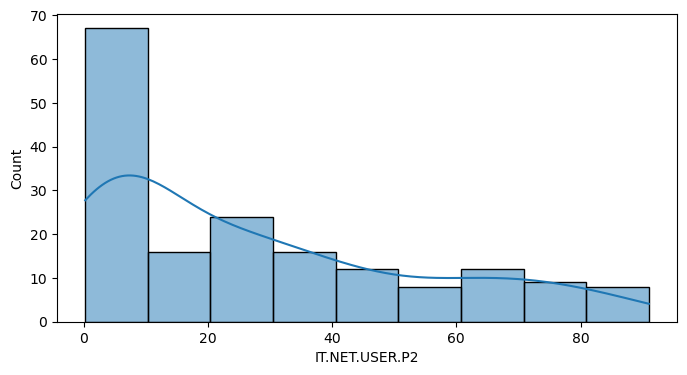

----------------------------------------
GDP per capita, PPP (constant 2011 international $)
----------------------------------------


count       172.00
mean      17453.92
std       19765.68
min         588.39
25%        3616.93
50%       10003.30
75%       24398.55
max      118585.16
Name: NY.GDP.PCAP.PP.KD, dtype: float64

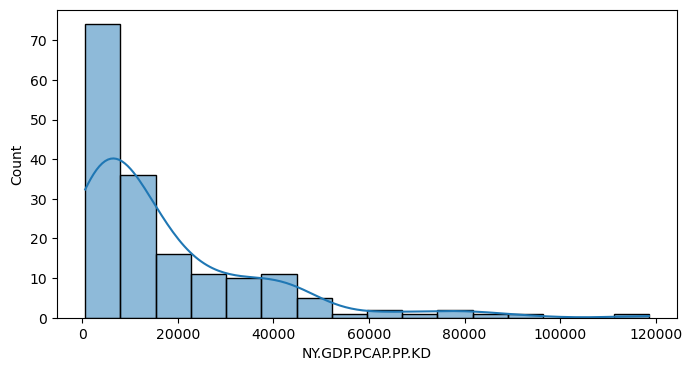

----------------------------------------
Enrolment in tertiary education, all programmes, both sexes (number)
----------------------------------------


count         172.00
mean       906605.99
std       2836151.77
min           563.00
25%         35518.75
50%        175139.00
75%        529444.50
max      26018988.00
Name: SE.TER.ENRL, dtype: float64

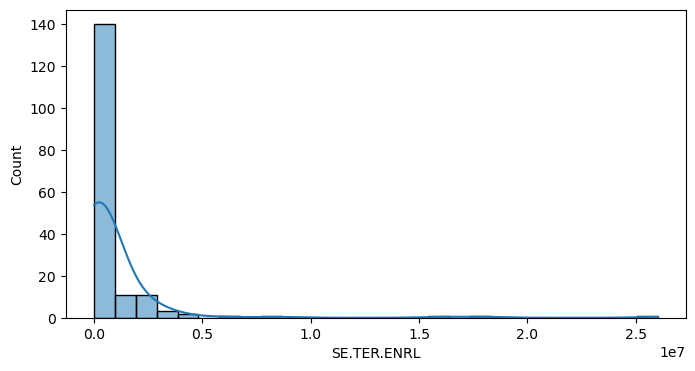

----------------------------------------
Gross enrolment ratio, tertiary, both sexes (%)
----------------------------------------


count    172.00
mean      31.39
std       24.85
min        0.48
25%        9.65
50%       24.51
75%       50.27
max       92.88
Name: SE.TER.ENRR, dtype: float64

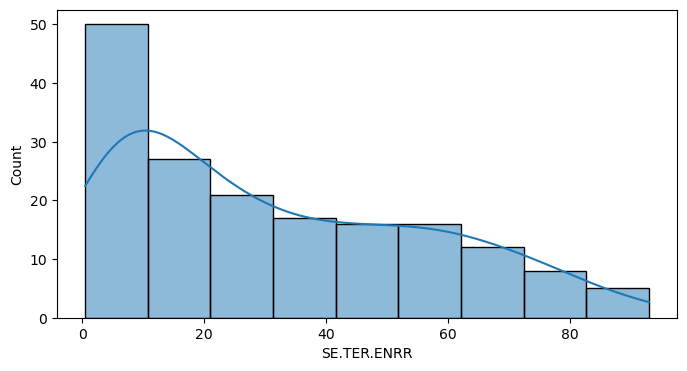

----------------------------------------
Population of the official age for upper secondary education, both sexes (number)
----------------------------------------


count         172.00
mean      2203419.60
std       8894656.62
min          2733.00
25%        113027.75
50%        381353.00
75%       1316368.38
max      94701416.00
Name: SP.SEC.UTOT.IN, dtype: float64

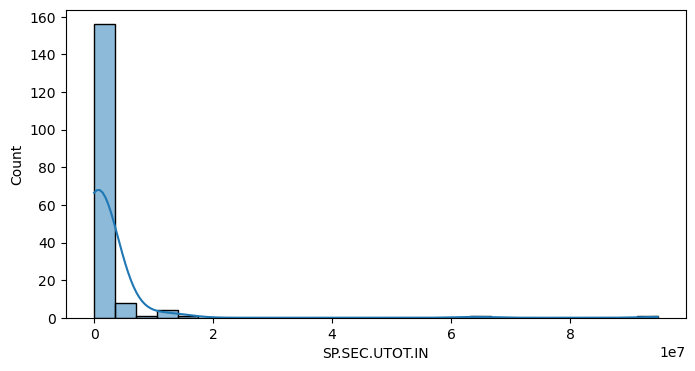

----------------------------------------
Population of the official age for tertiary education, both sexes (number)
----------------------------------------


count    1.720000e+02
mean     3.339143e+06
std      1.232853e+07
min      6.471000e+03
25%      2.292760e+05
50%      6.442345e+05
75%      2.358724e+06
max      1.132734e+08
Name: SP.TER.TOTL.IN, dtype: float64

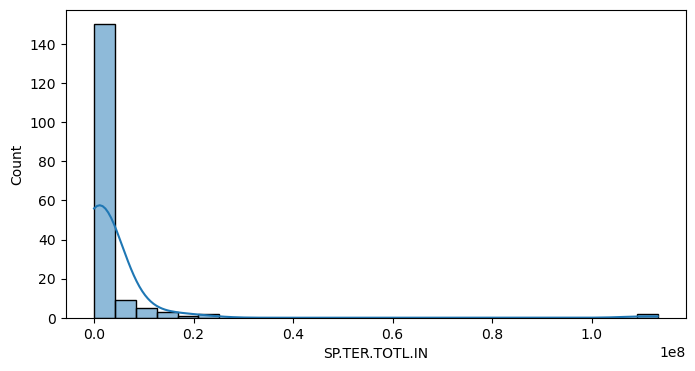

----------------------------------------
Net enrolment rate, upper secondary, both sexes (%)
----------------------------------------


count    172.00
mean      50.28
std       25.48
min        1.29
25%       29.34
50%       54.15
75%       70.06
max       97.07
Name: UIS.NER.3, dtype: float64

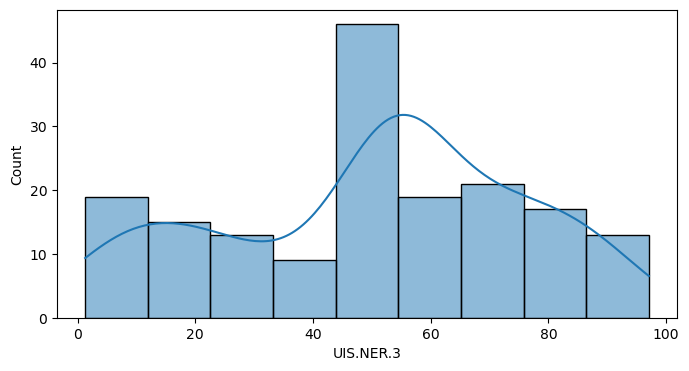

----------------------------------------
taux_hors_parcours_tertiaire
----------------------------------------


count    172.00
mean      68.61
std       24.85
min        7.12
25%       49.73
50%       75.49
75%       90.35
max       99.52
Name: taux_hors_parcours_tertiaire, dtype: float64

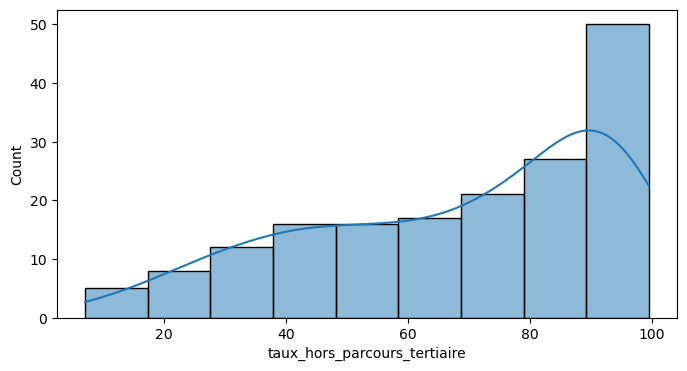

----------------------------------------
taux_hors_parcours_lycee
----------------------------------------


count    172.00
mean      49.72
std       25.48
min        2.93
25%       29.94
50%       45.85
75%       70.66
max       98.71
Name: taux_hors_parcours_lycee, dtype: float64

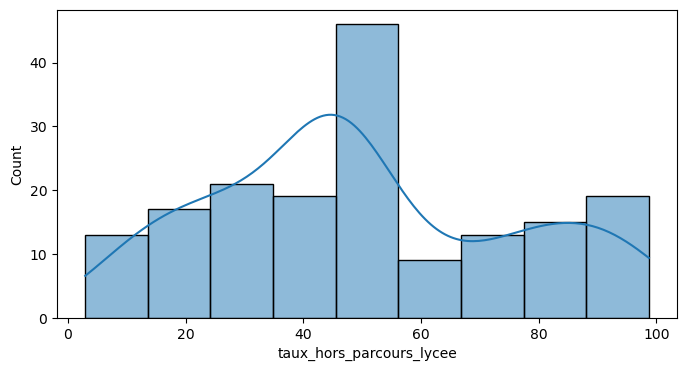

['IT.NET.USER.P2',
 'NY.GDP.PCAP.PP.KD',
 'SE.TER.ENRL',
 'SE.TER.ENRR',
 'SP.SEC.UTOT.IN',
 'SP.TER.TOTL.IN',
 'UIS.NER.3',
 'taux_hors_parcours_tertiaire',
 'taux_hors_parcours_lycee']

In [26]:
# Mapping pour afficher les titres des indicateurs calculés
mapping = df_data_clean.set_index('Indicator Code')["Indicator Name"].to_dict()

def analyse_indicateur(df, indicateur):
    titre(mapping.get(indicateur,indicateur))
    display(df[indicateur].describe().round(2))
    plt.figure(figsize = (8,4))
    sns.histplot(df[indicateur], kde = True)
    plt.show()

for indicateur in df_data_pivot.columns :
    analyse_indicateur(df_data_pivot,indicateur)

df_data_pivot.columns.tolist()

# Conclusion
On score les pays. Le problème est la ponderation car les indicateurs ne se valent pas, certains sont tres forts l'acces à imnternet et le pib. Il y a 3 étapes succesives pour arriver à un résultat serieux.

In [27]:
# Premier scoring sans ponderation
cols_scoring = ['IT.NET.USER.P2','NY.GDP.PCAP.PP.KD','SE.TER.ENRR','UIS.NER.3','taux_hors_parcours_tertiaire', 'taux_hors_parcours_lycee']
df_scoring = df_data_pivot[cols_scoring].rank(ascending=False).sum(axis=1).sort_values()
display(df_scoring.head(10))

# On insère une ponderation par ce que le PIB par habitant et l'accès à internet biaise le scoring en faveur des pays très riche.
poids = {
    'taux_hors_parcours_lycee'      : 3,
    'taux_hors_parcours_tertiaire'  : 3,
    'UIS.NER.3'                     : 2,
    'SE.TER.ENRR'                   : 2,
    'NY.GDP.PCAP.PP.KD'             : 1,
    'IT.NET.USER.P2'                : 1
}

df_scoring = (
    df_data_pivot[list(poids.keys())]
    .rank(ascending=False)
    .mul(poids)
    .sum(axis=1)
    .sort_values()
)

display(df_scoring.head(10))

# Ici c'est l'inverse, il s'agit de petit marché et la population(la taille du marché est faible) il faut pondérer avec la population totale des étudiants.
volume = df_data_pivot['SP.SEC.UTOT.IN'] + df_data_pivot['SP.TER.TOTL.IN']

df_scoring_volume = (
    df_data_pivot[list(poids.keys())]
    .rank(ascending=False)
    .mul(poids)
    .sum(axis=1)
    .mul(volume)
    .sort_values(ascending=False)
)
titre("PAYS FAVORABLE AU DEVLOPPEMENT D'ACADEMY")
display(df_scoring_volume.head(10))


Country Name
Luxembourg       355.0
Norway           356.0
Netherlands      363.0
Switzerland      364.0
Denmark          366.0
Sweden           367.0
Iceland          371.0
Singapore        373.0
United States    373.0
Austria          377.0
dtype: float64

Country Name
Luxembourg              876.0
Singapore               892.0
United Arab Emirates    897.0
Aruba                   921.0
Trinidad and Tobago     933.0
Suriname                934.0
Malaysia                940.0
Netherlands             941.5
Kuwait                  945.0
Austria                 945.5
dtype: float64

----------------------------------------
PAYS FAVORABLE AU DEVLOPPEMENT D'ACADEMY
----------------------------------------


Country Name
India                 2.239888e+11
China                 1.802355e+11
Indonesia             3.780823e+10
United States         3.542218e+10
Pakistan              3.220130e+10
Bangladesh            2.915841e+10
Brazil                2.834448e+10
Nigeria               2.468470e+10
Russian Federation    1.711137e+10
Mexico                1.705558e+10
dtype: float64

**Remarque** : Le suite est mainteant au marketing car meme si le marché est favorable, il y a des typologies de marchés et de clients. Nous ne connaissons pas  la structure du marché : accès, droit mais surtout concurence. À ce titre les USA et la Russie peut poser problème car leur marché sont loin d'atteindre la chine et l´inde en volume, ce qui compense, mais on un taux de concurence bien plus élevé.